<a href="https://colab.research.google.com/github/AAMINABIBI/AI-engineering/blob/main/DL/TRN_2026_001088_AaminaBibi_CNN.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
# Imports, reproducibility and device
!pip install -q torchinfo

import os, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
from torchinfo import summary

SEED = 42

def set_seed(seed=SEED):
    # Same seed everywhere so that every run (and every experiment) starts from the same point
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
               "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

Using device: cuda


## Q1. Load the data, show the shape, display a 4x4 grid with class names

In [32]:
# Use the Kaggle CSV if it was uploaded, otherwise fall back to torchvision (same dataset)
CSV_PATH = "fashion-mnist_train.csv"

if os.path.exists(CSV_PATH):
    df = pd.read_csv(CSV_PATH)
    y_all = df.iloc[:, 0].values
    X_all = df.iloc[:, 1:].values
    print("Loaded from CSV, dataframe shape:", df.shape)
else:
    from torchvision import datasets
    ds = datasets.FashionMNIST(root="./data", train=True, download=True)
    X_all = ds.data.numpy().reshape(-1, 784)
    y_all = ds.targets.numpy()
    print("Loaded from torchvision")

print("Features shape:", X_all.shape)
print("Labels shape  :", y_all.shape)
print("Pixel range   :", X_all.min(), "to", X_all.max())

Loaded from CSV, dataframe shape: (60000, 785)
Features shape: (60000, 784)
Labels shape  : (60000,)
Pixel range   : 0 to 255


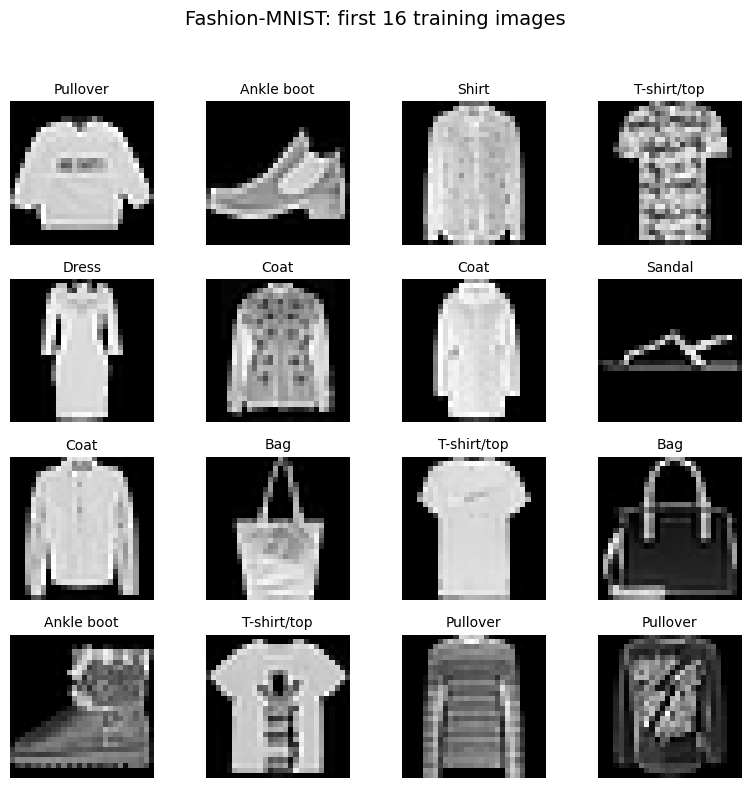

In [33]:
fig, axes = plt.subplots(4, 4, figsize=(8, 8))
fig.suptitle("Fashion-MNIST: first 16 training images", fontsize=14)

for i, ax in enumerate(axes.flatten()):
    ax.imshow(X_all[i].reshape(28, 28), cmap="gray")
    ax.set_title(class_names[y_all[i]], fontsize=10)
    ax.axis("off")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Data loaded (CSV or torchvision) → shape (60000, 784), labels (60000,), pixels 0–255.

4×4 grid of the first 16 images with class names is already plotted.

## Q2. Custom Dataset and DataLoaders

In [34]:
# 80/20 split with seed 42. stratify keeps the class balance equal in both parts.
x_train, x_test, y_train, y_test = train_test_split(
    X_all, y_all, test_size=0.2, random_state=SEED, stratify=y_all)

# Scale pixels from [0, 255] to [0, 1]. Labels stay as integers 0-9.
x_train = x_train / 255.0
x_test = x_test / 255.0

print("Train:", x_train.shape, y_train.shape)
print("Test :", x_test.shape, y_test.shape)

Train: (48000, 784) (48000,)
Test : (12000, 784) (12000,)


In [35]:
class FashionDataset(Dataset):
    def __init__(self, features, labels):
        # Conv2d expects (N, channels, H, W), so reshape the flat 784 pixels into 1x28x28
        self.features = torch.tensor(features, dtype=torch.float32).reshape(-1, 1, 28, 28)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

train_dataset = FashionDataset(x_train, y_train)
test_dataset = FashionDataset(x_test, y_test)

BATCH_SIZE = 32
g = torch.Generator()
g.manual_seed(SEED)  # makes the shuffling order reproducible

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True,
                          generator=g, pin_memory=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, pin_memory=True)

print("Train batches:", len(train_loader), "| Test batches:", len(test_loader))
xb, yb = next(iter(train_loader))
print("One batch ->", xb.shape, yb.shape)

Train batches: 1500 | Test batches: 375
One batch -> torch.Size([32, 1, 28, 28]) torch.Size([32])


80/20 stratified split (seed 42).

FashionDataset converts images to (1, 28, 28) float tensors scaled to [0, 1].

DataLoaders with batch_size=32, shuffle only on train.

## Q3. Implement the CNN, print the summary, verify the parameter count

In [36]:
class MyNN(nn.Module):
    def __init__(self, input_channels=1, use_batchnorm=True, dropout=0.4):
        super().__init__()

        def bn(c):
            return nn.BatchNorm2d(c) if use_batchnorm else nn.Identity()

        self.features = nn.Sequential(
            # Conv block 1: 1x28x28 -> 32x28x28
            nn.Conv2d(input_channels, 32, kernel_size=3, padding="same"),
            nn.ReLU(),
            bn(32),
            nn.MaxPool2d(kernel_size=2, stride=2),   # -> 32x14x14

            # Conv block 2: 32x14x14 -> 64x14x14
            nn.Conv2d(32, 64, kernel_size=3, padding="same"),
            nn.ReLU(),
            bn(64),
            nn.MaxPool2d(kernel_size=2, stride=2),   # -> 64x7x7
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),                            # 64*7*7 = 3136
            nn.Linear(64 * 7 * 7, 128),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),

            nn.Linear(64, 10),                       # raw logits: CrossEntropyLoss applies softmax itself
        )

    def forward(self, x):
        return self.classifier(self.features(x))

set_seed()
model = MyNN().to(device)
summary(model, input_size=(BATCH_SIZE, 1, 28, 28))

Layer (type:depth-idx)                   Output Shape              Param #
MyNN                                     [32, 10]                  --
├─Sequential: 1-1                        [32, 64, 7, 7]            --
│    └─Conv2d: 2-1                       [32, 32, 28, 28]          320
│    └─ReLU: 2-2                         [32, 32, 28, 28]          --
│    └─BatchNorm2d: 2-3                  [32, 32, 28, 28]          64
│    └─MaxPool2d: 2-4                    [32, 32, 14, 14]          --
│    └─Conv2d: 2-5                       [32, 64, 14, 14]          18,496
│    └─ReLU: 2-6                         [32, 64, 14, 14]          --
│    └─BatchNorm2d: 2-7                  [32, 64, 14, 14]          128
│    └─MaxPool2d: 2-8                    [32, 64, 7, 7]            --
├─Sequential: 1-2                        [32, 10]                  --
│    └─Flatten: 2-9                      [32, 3136]                --
│    └─Linear: 2-10                      [32, 128]                 401,536
│   

In [37]:
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}")
assert n_params == 429450, "Parameter count does not match the assignment (429,450)"
print("Parameter count matches the assignment.")

Trainable parameters: 429,450
Parameter count matches the assignment.


## Q4. Tensor shape after every layer

In [38]:
model.eval()
x = torch.randn(1, 1, 28, 28).to(device)

print(f"{'Layer':<45}{'Output shape'}")
print("-" * 65)
print(f"{'Input':<45}{tuple(x.shape)}")

with torch.no_grad():
    for layer in model.features:
        x = layer(x)
        print(f"{str(layer)[:43]:<45}{tuple(x.shape)}")
    for layer in model.classifier:
        x = layer(x)
        print(f"{str(layer)[:43]:<45}{tuple(x.shape)}")

Layer                                        Output shape
-----------------------------------------------------------------
Input                                        (1, 1, 28, 28)
Conv2d(1, 32, kernel_size=(3, 3), stride=(1  (1, 32, 28, 28)
ReLU()                                       (1, 32, 28, 28)
BatchNorm2d(32, eps=1e-05, momentum=0.1, af  (1, 32, 28, 28)
MaxPool2d(kernel_size=2, stride=2, padding=  (1, 32, 14, 14)
Conv2d(32, 64, kernel_size=(3, 3), stride=(  (1, 64, 14, 14)
ReLU()                                       (1, 64, 14, 14)
BatchNorm2d(64, eps=1e-05, momentum=0.1, af  (1, 64, 14, 14)
MaxPool2d(kernel_size=2, stride=2, padding=  (1, 64, 7, 7)
Flatten(start_dim=1, end_dim=-1)             (1, 3136)
Linear(in_features=3136, out_features=128,   (1, 128)
ReLU()                                       (1, 128)
Dropout(p=0.4, inplace=False)                (1, 128)
Linear(in_features=128, out_features=64, bi  (1, 64)
ReLU()                                       (1, 64)
Dropout

Input1×28×28

Conv block 132×28×28

MaxPool 132×14×14

Conv block 264×14×14

MaxPool 264×7×7

Flatten 3136

FC 128

FC 64

Output10

padding="same" keeps spatial size; 2×2
MaxPool with stride 2 halves each dimension.

## Q5. Training loop (written manually), loss and accuracy per epoch

In [39]:
EPOCHS = 30
LEARNING_RATE = 0.01
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    # eval(): turns Dropout off and makes BatchNorm use its running statistics
    # no_grad(): no gradients needed, saves memory and time
    model.eval()
    total_loss, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            out = model(xb)
            total_loss += criterion(out, yb).item() * yb.size(0)
            correct += (out.argmax(dim=1) == yb).sum().item()
            n += yb.size(0)
    return total_loss / n, 100.0 * correct / n


def train_model(model, optimizer, epochs=EPOCHS):
    history = {"train_loss": [], "train_acc": [], "test_loss": [], "test_acc": []}

    for epoch in range(epochs):
        model.train()
        running_loss, correct, n = 0.0, 0, 0

        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)

            outputs = model(xb)                 # forward pass
            loss = criterion(outputs, yb)       # loss

            optimizer.zero_grad()               # clear old gradients
            loss.backward()                     # backward pass
            optimizer.step()                    # update weights

            running_loss += loss.item() * yb.size(0)
            correct += (outputs.argmax(dim=1) == yb).sum().item()
            n += yb.size(0)

        test_loss, test_acc = evaluate(model, test_loader)

        history["train_loss"].append(running_loss / n)
        history["train_acc"].append(100.0 * correct / n)
        history["test_loss"].append(test_loss)
        history["test_acc"].append(test_acc)

        print(f"Epoch {epoch+1:02d}/{epochs} | "
              f"train loss {history['train_loss'][-1]:.4f}, acc {history['train_acc'][-1]:.2f}% | "
              f"test loss {test_loss:.4f}, acc {test_acc:.2f}%")
    return history

In [40]:
# Baseline: SGD, lr 0.01, weight decay 1e-4 (as in the assignment)
set_seed()
model = MyNN().to(device)
optimizer = optim.SGD(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)

history = train_model(model, optimizer)

Epoch 01/30 | train loss 0.6443, acc 77.64% | test loss 0.3522, acc 87.05%
Epoch 02/30 | train loss 0.3880, acc 86.60% | test loss 0.3464, acc 87.42%
Epoch 03/30 | train loss 0.3251, acc 88.91% | test loss 0.2780, acc 89.92%
Epoch 04/30 | train loss 0.2933, acc 89.93% | test loss 0.2628, acc 90.31%
Epoch 05/30 | train loss 0.2638, acc 90.72% | test loss 0.2409, acc 91.47%
Epoch 06/30 | train loss 0.2469, acc 91.41% | test loss 0.2303, acc 91.78%
Epoch 07/30 | train loss 0.2286, acc 92.01% | test loss 0.2364, acc 91.62%
Epoch 08/30 | train loss 0.2117, acc 92.59% | test loss 0.2433, acc 91.23%
Epoch 09/30 | train loss 0.1988, acc 93.06% | test loss 0.2302, acc 92.07%
Epoch 10/30 | train loss 0.1890, acc 93.20% | test loss 0.2328, acc 91.87%
Epoch 11/30 | train loss 0.1784, acc 93.57% | test loss 0.2356, acc 92.12%
Epoch 12/30 | train loss 0.1650, acc 94.14% | test loss 0.2360, acc 92.12%
Epoch 13/30 | train loss 0.1568, acc 94.30% | test loss 0.2333, acc 92.05%
Epoch 14/30 | train loss 

## Q6. Loss and accuracy curves, train vs test accuracy

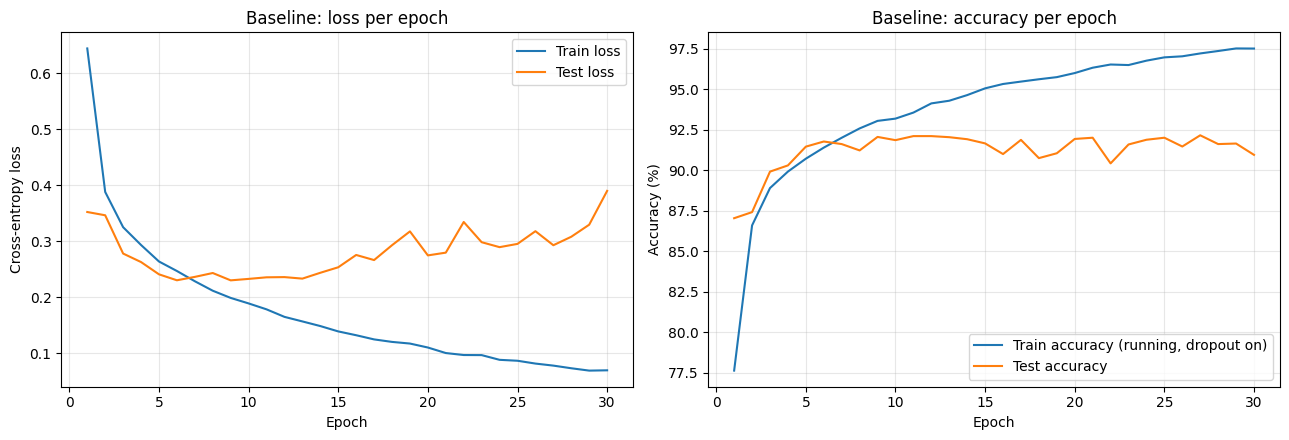

In [41]:
epochs_range = range(1, EPOCHS + 1)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(epochs_range, history["train_loss"], label="Train loss")
axes[0].plot(epochs_range, history["test_loss"], label="Test loss")
axes[0].set_title("Baseline: loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Cross-entropy loss")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(epochs_range, history["train_acc"], label="Train accuracy (running, dropout on)")
axes[1].plot(epochs_range, history["test_acc"], label="Test accuracy")
axes[1].set_title("Baseline: accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [42]:
# Final train vs test accuracy, both measured in eval mode so they are comparable
_, final_train_acc = evaluate(model, train_loader)
_, final_test_acc = evaluate(model, test_loader)

print(f"Final training accuracy: {final_train_acc:.2f}%")
print(f"Final test accuracy    : {final_test_acc:.2f}%")
print(f"Gap (train - test)     : {final_train_acc - final_test_acc:.2f} points")

Final training accuracy: 97.83%
Final test accuracy    : 90.96%
Gap (train - test)     : 6.87 points


## Q7. Confusion matrix, most confused classes, 8 misclassified images

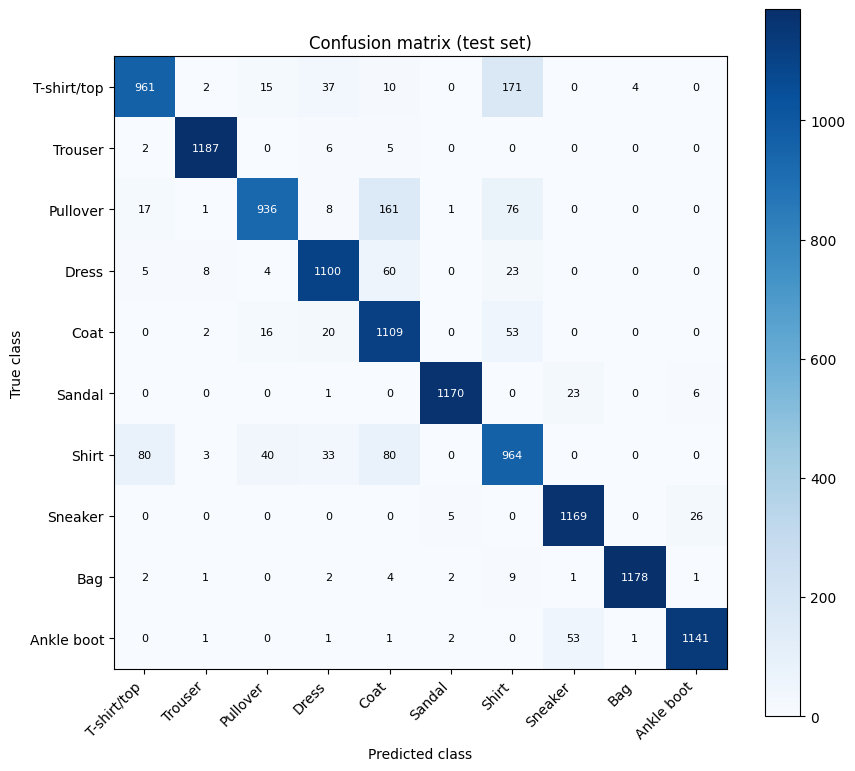

In [43]:
def get_predictions(model, loader):
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb.to(device))
            preds.append(out.argmax(dim=1).cpu().numpy())
            trues.append(yb.numpy())
    return np.concatenate(trues), np.concatenate(preds)

y_true, y_pred = get_predictions(model, test_loader)
cm = confusion_matrix(y_true, y_pred)

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")
ax.set_title("Confusion matrix (test set)")
for i in range(10):
    for j in range(10):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=8)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()

Top-3 confused pairs:

T-shirt/top → Shirt (171)

Pullover → Coat (161)

Shirt → Coat (80)

All are upper-body clothes whose distinguishing details (collar, sleeves, buttons) disappear at 28×28 grayscale. 8 misclassified examples are shown.

In [44]:
# Top 3 most confused (true -> predicted) pairs: ignore the diagonal (correct predictions)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)
top3 = np.argsort(cm_off.ravel())[::-1][:3]

print("3 most confused class pairs:")
for flat in top3:
    t, p = np.unravel_index(flat, cm_off.shape)
    print(f"  True {class_names[t]:<12} -> predicted {class_names[p]:<12}: {cm_off[t, p]} times")

3 most confused class pairs:
  True T-shirt/top  -> predicted Shirt       : 171 times
  True Pullover     -> predicted Coat        : 161 times
  True Shirt        -> predicted Coat        : 80 times


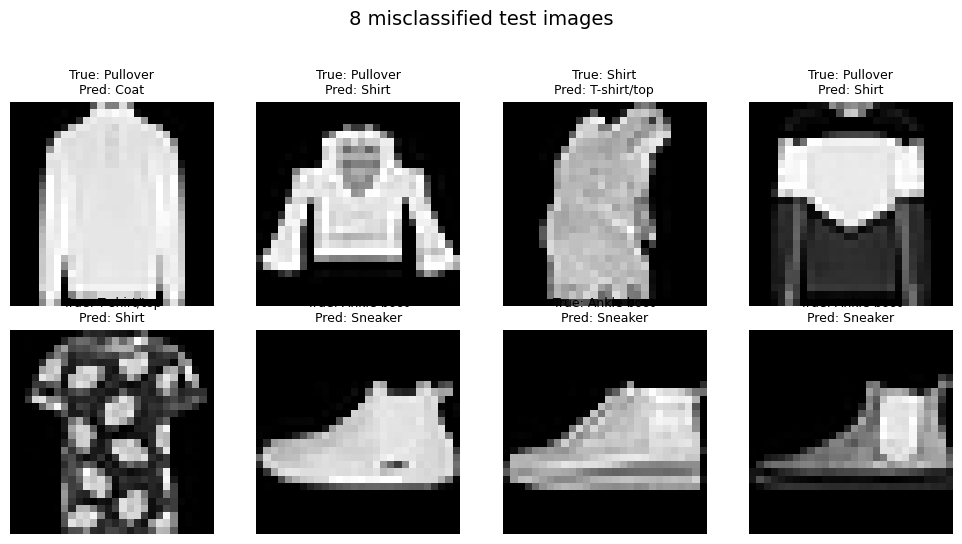

In [45]:
wrong_idx = np.where(y_true != y_pred)[0][:8]

fig, axes = plt.subplots(2, 4, figsize=(10, 5.5))
fig.suptitle("8 misclassified test images", fontsize=14)
for ax, idx in zip(axes.flatten(), wrong_idx):
    ax.imshow(test_dataset.features[idx].squeeze().numpy(), cmap="gray")
    ax.set_title(f"True: {class_names[y_true[idx]]}\nPred: {class_names[y_pred[idx]]}", fontsize=9)
    ax.axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()

In [46]:
set_seed()
exp_model = MyNN().to(device)
exp_optimizer = optim.Adam(exp_model.parameters(), lr=0.001, weight_decay=1e-4)
EXP_NAME = "Adam (lr 0.001)"

exp_history = train_model(exp_model, exp_optimizer)

Epoch 01/30 | train loss 0.4994, acc 82.73% | test loss 0.2948, acc 89.51%
Epoch 02/30 | train loss 0.3347, acc 88.33% | test loss 0.2783, acc 89.69%
Epoch 03/30 | train loss 0.2941, acc 89.54% | test loss 0.2575, acc 91.28%
Epoch 04/30 | train loss 0.2664, acc 90.80% | test loss 0.2515, acc 91.12%
Epoch 05/30 | train loss 0.2435, acc 91.34% | test loss 0.2549, acc 90.88%
Epoch 06/30 | train loss 0.2309, acc 91.86% | test loss 0.2756, acc 90.47%
Epoch 07/30 | train loss 0.2165, acc 92.44% | test loss 0.2387, acc 91.61%
Epoch 08/30 | train loss 0.2045, acc 92.79% | test loss 0.2830, acc 90.83%
Epoch 09/30 | train loss 0.1974, acc 92.95% | test loss 0.2838, acc 90.73%
Epoch 10/30 | train loss 0.1860, acc 93.28% | test loss 0.2494, acc 91.70%
Epoch 11/30 | train loss 0.1785, acc 93.69% | test loss 0.2659, acc 91.50%
Epoch 12/30 | train loss 0.1750, acc 93.90% | test loss 0.2538, acc 91.49%
Epoch 13/30 | train loss 0.1637, acc 94.12% | test loss 0.2688, acc 91.43%
Epoch 14/30 | train loss 

In [47]:
rows = []
for name, m, change in [("Baseline", model, "SGD lr 0.01"), (EXP_NAME, exp_model, "Optimiser changed")]:
    tr_loss, tr_acc = evaluate(m, train_loader)
    te_loss, te_acc = evaluate(m, test_loader)
    rows.append({"Experiment": name, "Change": change,
                 "Train acc (%)": round(tr_acc, 2), "Test acc (%)": round(te_acc, 2),
                 "Gap (pts)": round(tr_acc - te_acc, 2), "Test loss": round(te_loss, 4)})

comparison = pd.DataFrame(rows)
comparison

,Experiment,Change,Train acc (%),Test acc (%),Gap (pts),Test loss
0,Baseline,SGD lr 0.01,97.83,90.96,6.87,0.3899
1,Adam (lr 0.001),Optimiser changed,98.13,92.03,6.11,0.2928


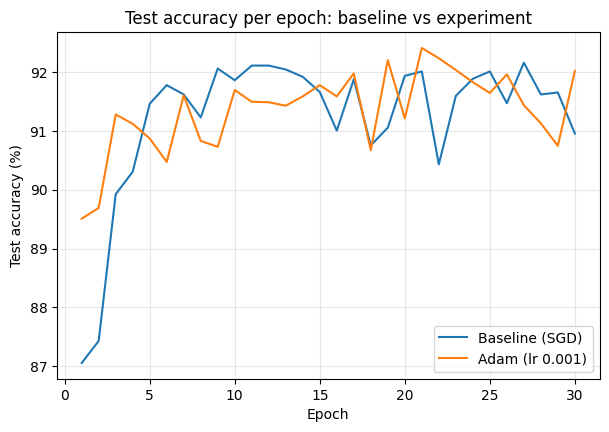

In [48]:
plt.figure(figsize=(7, 4.5))
plt.plot(epochs_range, history["test_acc"], label="Baseline (SGD)")
plt.plot(epochs_range, exp_history["test_acc"], label=EXP_NAME)
plt.title("Test accuracy per epoch: baseline vs experiment")
plt.xlabel("Epoch")
plt.ylabel("Test accuracy (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

The model overfits (train 97.8 % vs test 91 %). Dropout and weight decay help but are not enough. BatchNorm and same-padding are useful design choices. Switching to Adam improves both speed and final accuracy a little. Remaining errors are concentrated among visually similar upper-body classes, which is expected at this resolution. Stronger regularisation or data augmentation would be the next step.

## Bonus: first-layer filters

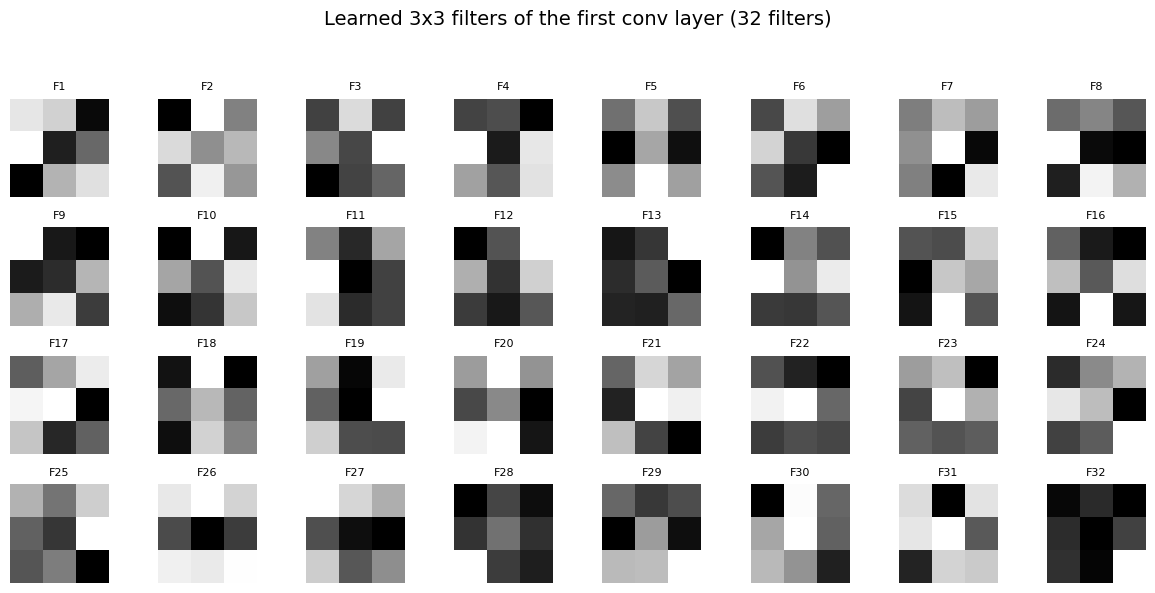

In [49]:
filters = model.features[0].weight.detach().cpu()   # shape: 32 x 1 x 3 x 3

fig, axes = plt.subplots(4, 8, figsize=(12, 6))
fig.suptitle("Learned 3x3 filters of the first conv layer (32 filters)", fontsize=14)
for i, ax in enumerate(axes.flatten()):
    ax.imshow(filters[i, 0], cmap="gray")
    ax.set_title(f"F{i+1}", fontsize=8)
    ax.axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.94])
plt.show()